![Banner](../../../../Images/Banner/03_spatial_analysis/03_04_banner_spatial_analysis_Multi_Criteria.png)



# Multi-Criteria Suitability Modeling (MCSM)



This notebook provides an introduction to Multi-Criteria Suitability Modeling (MCSM), a collection of spatial analysis techniques used to identify optimal locations based on multiple factors. You will learn the concepts, workflow, and practical applications of suitability modeling using both vector and raster data, along with case studies and hands-on examples.

Ten notebooks turn a set of criteria into a ranked map, then test how far the weights and the data move that map.

- **Multi-Criteria Suitability Modeling (MCSM).** This notebook. What suitability modeling asks, and how Boolean, weighted, and fuzzy overlays combine the same criteria.
- **Vector-based Suitability Analysis.** Load New York counties, join attributes, reproject, and map the raw variables for a clinic-siting case.
- **Deriving Criteria for Clinic Site Selection.** Build a health-need index, an ICU-bed location quotient, a rurality score, and a distance-to-hub criterion.
- **Categorical (Boolean) Suitability Analysis.** Crisp thresholds, AND and OR overlays, k-of-n, and how the map changes when a threshold moves.
- **Weighted Suitability Analysis.** Min-max and percentile normalisation, weighted linear combination, a hybrid model, and a first robustness check.
- **Fuzzy Logic Foundations for Suitability Modeling.** Membership functions, hedges, and the overlay operators that replace a hard cut.
- **Fuzzy Suitability for Polygons.** Apply those memberships to the New York counties and compare the ranks with the weighted scores.
- **Fuzzy Suitability for Rasters.** Derive slope, aspect, position, and stream distance from a 90 m DEM and site a solar farm with a fuzzy overlay.
- **Advanced Fuzzy Suitability: Sensitivity, Weighting, and Rule-based Inference.** Gamma and parameter sensitivity, weighted fuzzy operators, and a Mamdani rule-based model.
- **Sensitivity and Uncertainty Analysis of MCSM.** One-at-a-time weight shifts, Dirichlet Monte Carlo, Sobol indices, and the effect of elevation error and grid scale.

Library: `geolattice.spatial_analysis.multi_criteria_suitability_analysis`

## Overview

**Suitability analysis** asks *where* an activity, facility, or land use is most appropriate by measuring how well every location satisfies a collection of criteria. It is the spatial expression of **Multi-Criteria Decision Analysis (MCDA)**:

| MCDA concept | Spatial equivalent |
|---|---|
| **Alternative** | A location: a raster cell, a polygon, a site |
| **Criterion** | A spatial layer (distance, slope, population density) |
| **Weight** | Relative importance of each criterion |
| **Composite score** | A suitability surface or ranked map |

Suitability maps are not predictions: they are ranked evidence summaries. They make assumptions explicit (which factors matter, how they are combined, what thresholds or weights are used) and must be validated against independent observations or expert judgement.

### Why is it challenging?

Several challenges make MCSM more than simple map overlay:

1. **Commensurability**: criteria come in different units (km, %, persons/km2) and must be standardised before combination.
2. **Directionality**: some criteria are "higher is better" (population need), others "lower is better" (slope, distance).
3. **Threshold uncertainty**: crisp Boolean cuts (e.g. slope < 5 degrees) ignore the fact that a site at 5.1 degrees is nearly as good as one at 4.9 degrees.
4. **Weight elicitation**: weights reflect value judgements; different stakeholders prefer different emphases.
5. **Sensitivity**: the top-ranked sites may change dramatically if a weight or threshold shifts slightly.

This chapter addresses all five, moving from the simplest (Boolean) through to probabilistic sensitivity analysis.

## General MCSM Workflow

Every suitability model, regardless of technique, follows the same logical arc:

```
+----------------------------------------------------------------------+
|  1. DEFINE THE GOAL AND DECISION UNIT                                |
|     What are we siting / ranking?  What is the spatial unit?         |
+---------------------------+------------------------------------------+
                            |
                            v
+----------------------------------------------------------------------+
|  2. ASSEMBLE CRITERIA                                                |
|     Collect raw layers (census, DEM, land cover, road network)       |
+---------------------------+------------------------------------------+
                            |
                            v
+----------------------------------------------------------------------+
|  3. DERIVE AND STANDARDISE CRITERIA                                  |
|     Indices, location quotients, distance transforms;                |
|     min-max / percentile / fuzzy normalisation                       |
+---------------------------+------------------------------------------+
                            |
                            v
+----------------------------------------------------------------------+
|  4. COMBINE CRITERIA                                                 |
|     Boolean (AND / OR / k-of-n)  -->  Part I                        |
|     Weighted Linear Combination  -->  Part I                        |
|     Fuzzy overlay                -->  Part II                       |
|     Rule-based (Mamdani FIS)     -->  Part II                       |
+---------------------------+------------------------------------------+
                            |
                            v
+----------------------------------------------------------------------+
|  5. VALIDATE AND TEST SENSITIVITY                                    |
|     Rank stability, OAT perturbation, Monte Carlo, SALib             |
+---------------------------+------------------------------------------+
                            |
                            v
+----------------------------------------------------------------------+
|  6. COMMUNICATE AND DECIDE                                           |
|     Maps, ranked lists, scenario comparisons, equity summaries       |
+----------------------------------------------------------------------+
```

Network analysis (Part IV) enters the workflow at **Steps 2-3**: travel time to the nearest facility, isochrone coverage, or 2SFCA accessibility scores become suitability criteria just like any other spatial variable.



## Methods at a Glance

### Boolean (Categorical) Suitability

Each criterion becomes a binary mask: a location either passes or fails a hard threshold. Masks are combined with logical **AND** (must satisfy all), **OR** (must satisfy at least one), or **k-of-n** (must satisfy at least *k* out of *n* criteria).

- **Pros:** Transparent and easy to explain to non-technical audiences.
- **Cons:** Sensitive to threshold choice; discards all information within each category.

### Weighted Linear Combination (WLC)

Criteria are standardised to a common scale and summed with expert-assigned weights:

$$S = \sum_{i=1}^{n} w_i \cdot x_i, \quad \sum w_i = 1, \quad w_i \geq 0$$

WLC allows **full trade-off**: a weak score on one criterion can be compensated by a strong score on another. Hard constraints (Boolean masks applied *after* scoring) prevent physically impossible combinations from appearing in the final result.

- **Pros:** Continuous output; easy to adjust weights.
- **Cons:** Full compensation may let poor-performing locations score highly overall.

### Fuzzy Logic Suitability

Instead of binary pass/fail, each location receives a **membership value** in [0, 1] indicating its *degree* of suitability for each criterion. Membership functions replace crisp thresholds:

| Function | Shape | Best for |
|---|---|---|
| `large` / `ms_large` | S-shaped | "More is better" (need, demand) |
| `small` / `ms_small` | Reversed S | "Less is better" (distance, slope) |
| `near` | Symmetric bell | "Close to a target value is best" |
| `gaussian` | Gaussian bell | Smooth, symmetric preference |
| `linear` | Trapezoid / ramp | Simple linear transition |

Memberships are combined with **fuzzy overlay operators** (AND = min, OR = max, PRODUCT, SUM, GAMMA) that trade off between full-conjunction and full-disjunction strategies.

- **Pros:** Handles boundary uncertainty; eliminates abrupt threshold effects.
- **Cons:** Requires more parameter choices (function type, spread, crossover point).

### Rule-Based Inference (Mamdani FIS)

A **Fuzzy Inference System** (FIS) encodes expert knowledge as IF-THEN rules over fuzzy sets:

```
IF   health_need IS high   AND   icu_gap IS large
THEN suitability IS very_high
```

The vectorised Mamdani FIS in `geolattice` evaluates all rules simultaneously for every spatial unit and defuzzifies the result to a numeric suitability score.

- **Pros:** Expert-interpretable; captures non-linear interactions between criteria.
- **Cons:** Rule base grows large with many criteria; requires careful validation.

### Sensitivity and Uncertainty Analysis

| Technique | What it tests |
|---|---|
| **OAT (One-at-a-time) perturbation** | Impact of changing a single weight by delta while others are fixed |
| **Dirichlet Monte Carlo** | Distribution of rank outcomes over randomly drawn weight vectors |
| **SALib Sobol / Morris** | Global variance-based sensitivity indices |
| **Data uncertainty** | Propagation of input measurement error into the suitability surface |



## Case Studies

This chapter uses two complementary case studies, each designed to illustrate a different geometry type and thematic domain.

### New York Rural Health Clinic (Parts I-II, vector)

A regional health network wants to open a new primary-care and telehealth clinic in New York State. Planners look for counties that satisfy the following four criteria:

| # | Criterion | Measure | Direction |
|---|---|---|---|
| 1 | Health-care need | Composite of elderly share + poverty rate | Higher -> better |
| 2 | Hospital capacity gap | ICU beds per capita vs state average (location quotient) | Fewer relative beds -> better |
| 3 | Rurality | USDA Rural-Urban Continuum Code (RUCC) | Higher code -> more rural -> better |
| 4 | Proximity to referral hub | Euclidean distance to nearest academic medical centre | Shorter -> better |

**Data:** `Data/03_spatial_analysis/MCSM_data/ny_counties.gpkg` (62 counties, EPSG:5070)  
**Methods covered:** Boolean (Part I), WLC (Part I), Fuzzy vector overlay (Part II)

> **Note:** The data are real but several years old (approximately 2018), and the hub list is illustrative. The goal is to learn the methods, not to make an actual siting recommendation.

### Solar-Farm Site Selection (Part II, raster)

A renewable-energy developer needs candidate parcels for a utility-scale solar farm. Suitable cells must satisfy:

| # | Criterion | Derived from | Direction |
|---|---|---|---|
| 1 | Low slope | 90 m DEM via richdem | Flatter -> better |
| 2 | Favourable aspect | DEM -> aspect calculation | South-facing -> better |
| 3 | Not in water / forest | Land-cover mask | Hard constraint |
| 4 | Not on steep terrain | Slope threshold | Hard constraint |

**Data:** `Data/03_spatial_analysis/MCSM_data/` (90 m DEM rasters, EPSG:5070)  
**Methods covered:** Fuzzy raster overlay (Part II), advanced fuzzy + Mamdani FIS (Part II), sensitivity analysis (Part III)

### Synthetic Network Region (Part IV)

A synthetic road network and census-tract dataset in `Data/00_shared/data_spatial_net/` supports all network-analysis notebooks with reproducible, offline examples that apply directly to real OSMnx downloads.

| Dataset file | Contents |
|---|---|
| `roads.graphml` | Synthetic planar road graph |
| `towns.geojson` | Point facilities (hospitals, clinics) |
| `tracts.geojson` | Population polygons with age / poverty attributes |



## GeoLattice API Overview

Both modules live inside `geolattice.spatial_analysis`.

### `multi_criteria_suitability_analysis`

#### Criterion derivation and standardisation

| Function | Description |
|---|---|
| `minmax_normalize(series, direction)` | Min-max normalisation; `direction='higher'` or `'lower'` |
| `percentile_rank_normalize(series, direction)` | Percentile-rank normalisation (0-100 -> 0-1) |
| `location_quotient(series)` | County / state-average ratio for capacity gap analysis |
| `composite_index(df, cols, weights)` | Weighted sum of already-normalised columns into a composite index |

#### Fuzzy membership functions

| Function | Shape | Key parameters |
|---|---|---|
| `large(x, midpoint, spread)` | S-curve (large = better) | midpoint, spread |
| `small(x, midpoint, spread)` | Reversed S (small = better) | midpoint, spread |
| `ms_large(x, midpoint, spread)` | MS-style large | midpoint, spread |
| `ms_small(x, midpoint, spread)` | MS-style small | midpoint, spread |
| `near(x, midpoint, spread)` | Symmetric bell | midpoint, spread |
| `gaussian(x, mean, std)` | Gaussian bell | mean, std |
| `linear(x, low, high, direction)` | Trapezoid ramp | low, high, direction |
| `spread_for_small(midpoint, p_lo)` | Helper: compute spread so that `small(p_lo)` equals 0.1 | -- |

#### Fuzzy hedges

| Function | Effect |
|---|---|
| `very(membership)` | Concentration: squares the membership (stronger requirement) |
| `somewhat(membership)` | Dilation: square-roots the membership (weaker requirement) |

#### Overlay and combination operators

| Function | Description |
|---|---|
| `categorical_overlay(df, criteria, logic)` | Boolean AND / OR / k-of-n overlay on a GeoDataFrame |
| `weighted_linear_combination(df, cols, weights)` | WLC with optional normalisation step |
| `hybrid_suitability(df, bool_col, wlc_col)` | Mask WLC result by Boolean constraint layer |
| `overlay(arrays, type)` | Fuzzy overlay: 'AND', 'OR', 'PRODUCT', 'SUM', 'GAMMA' |
| `weighted_fuzzy_overlay(arrays, weights, type)` | Weighted version of fuzzy overlay |
| `mamdani_fis(rules, memberships, defuzz)` | Vectorised Mamdani fuzzy inference system |

#### Sensitivity and uncertainty tools

| Function | Description |
|---|---|
| `oat_perturbation(model_fn, base_weights, delta)` | One-at-a-time weight perturbation; returns rank-change table |
| `monte_carlo_weights(model_fn, n_samples, seed)` | Dirichlet Monte Carlo weight sampling |
| `sobol_indices(model_fn, bounds, n)` | SALib Sobol variance-based sensitivity indices |
| `jaccard_similarity(map_a, map_b, top_k)` | Jaccard overlap of top-k ranked units between two maps |

---

### `network_analysis`

#### Graph construction and embedding

| Function | Description |
|---|---|
| `haversine_length(G)` | Add `length_m` edge attribute via haversine formula |
| `projected_length(G)` | Add Euclidean `length_m` from projected node coordinates |
| `graph_to_gdfs(G)` | Convert NetworkX graph to (nodes GDF, edges GDF) |
| `gdfs_to_graph(nodes_gdf, edges_gdf)` | Rebuild graph from GeoDataFrames |
| `circuity(G)` | Network circuity index (route / straight-line distance ratio) |
| `kansky_indices(G)` | Alpha, beta, gamma network topology indices |
| `is_planar(G)` | Test planarity of the network graph |

#### Spatial weight matrices and adjacency

| Function | Description |
|---|---|
| `weights_to_graph(W)` | Convert `libpysal` spatial weights to NetworkX graph |
| `lines_to_graph(gdf)` | Build graph from a LineString GeoDataFrame (shared endpoints) |
| `morans_i(y, W)` | Moran's I spatial autocorrelation on a weight matrix |

#### Routing and accessibility

| Function | Description |
|---|---|
| `snap_to_network(gdf, G)` | Snap point features to nearest network node |
| `shortest_path(G, origin, dest, weight)` | Dijkstra shortest path; returns node list + cost |
| `od_matrix(G, origins, dests, weight)` | Full origin-destination travel-cost matrix |
| `isochrone(G, source, cutoffs, weight)` | Multi-source Dijkstra service-area polygons |
| `nearest_facility(G, demand, supply, weight)` | Nearest facility + travel cost for every demand node |
| `two_sfca(G, demand, supply, d_thresh, weight)` | Two-step floating catchment area accessibility score |
| `e2sfca(G, demand, supply, decay_fn, weight)` | Enhanced 2SFCA with distance-decay function |
| `lorenz_gini(access_series)` | Lorenz curve + Gini coefficient for equity assessment |
| `closure_impact(G, edges_to_remove)` | Travel-time delta after removing a set of edges |



## Dependencies

### Core (required for all notebooks)

```bash
pip install geolattice geopandas pandas numpy matplotlib mapclassify
```

### Part I: Vector suitability

```bash
pip install geolattice geopandas scipy
```

### Part II: Fuzzy suitability (rasters)

```bash
pip install geolattice rasterio richdem
```

### Part III: Sensitivity and uncertainty

```bash
pip install geolattice SALib
```

### Part IV: Network analysis

```bash
pip install geolattice osmnx networkx libpysal
```

### Full environment (recommended)

```bash
pip install geolattice geopandas pandas numpy matplotlib mapclassify \
            scipy rasterio richdem SALib \
            osmnx networkx libpysal
```

Or with conda:

```bash
conda install -c conda-forge geolattice geopandas rasterio richdem osmnx libpysal salib
```



## Conceptual Overview: MCSM Techniques Compared

The cell below draws a compact visual comparison of the three main combination strategies on a toy two-criterion example, alongside a plot of the most common fuzzy membership functions.

**Installation.** This notebook needs installation option 1 (vector, raster, CRS and visualization): `pip install "geolattice[core]"`. See "Installation options" in the GeoLattice README.

/tmp/ipykernel_240653/4177678012.py:110: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()  # tighten spacing between panels


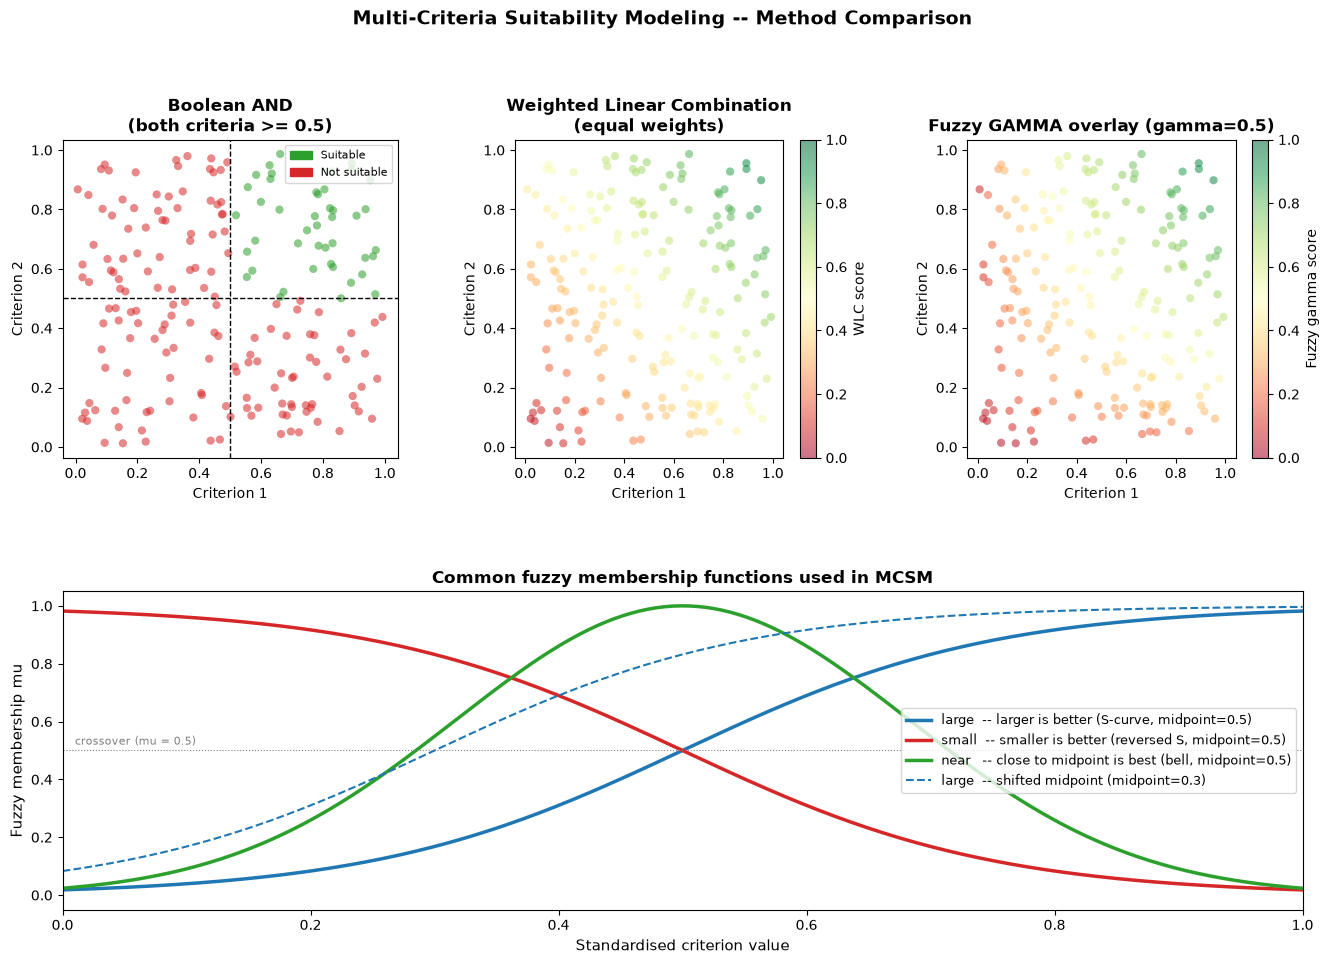

In [1]:
# Display matplotlib figures inline in this Jupyter notebook.
%matplotlib inline

# Third-party numeric / plotting stack for the method-comparison figure.
import numpy as np  # array ops for toy criteria and membership curves
import matplotlib.pyplot as plt  # figure and axes creation
import matplotlib.patches as mpatches  # legend patches for Boolean classes
from matplotlib.gridspec import GridSpec  # 2x3 layout for comparison panels

# ===================================================================
# Toy data: 200 random locations with two criteria on a 0-1 scale.
# Used only to illustrate Boolean AND, WLC, and fuzzy GAMMA visually.
# ===================================================================
rng = np.random.default_rng(42)  # reproducible RNG for the scatter demo
n = 200  # number of synthetic locations
c1 = rng.uniform(0, 1, n)  # criterion 1 (e.g. normalised need)
c2 = rng.uniform(0, 1, n)  # criterion 2 (e.g. normalised rurality)

# Boolean AND: a location is suitable only if both criteria are at least 0.5.
bool_mask = (c1 >= 0.5) & (c2 >= 0.5)  # crisp pass/fail mask

# Weighted linear combination with equal weights (full trade-off).
wlc = 0.5 * c1 + 0.5 * c2  # continuous suitability score in [0, 1]

# Fuzzy GAMMA overlay: blend fuzzy AND (min) and fuzzy OR (max).
fuzzy_and = np.minimum(c1, c2)  # fuzzy AND = element-wise minimum
fuzzy_or = np.maximum(c1, c2)  # fuzzy OR = element-wise maximum
gamma = 0.5  # 0 -> pure AND, 1 -> pure OR; 0.5 balances both
fuzzy_gamma = (fuzzy_and ** (1 - gamma)) * (fuzzy_or ** gamma)  # gamma product blend

# ===================================================================
# Membership function definitions (pure NumPy, matching ArcGIS-style shapes).
# ===================================================================
x = np.linspace(0, 1, 300)  # dense x-grid for plotting membership curves


# Membership: larger values score closer to 1 (S-curve).
def ms_large(x, mid=0.5, spread=5):
    """S-curve: 'larger is better'."""
    return 1 / (1 + np.exp(-spread * (x - mid)))  # logistic rising through midpoint


# Membership: smaller values score closer to 1 (reversed S-curve).
def ms_small(x, mid=0.5, spread=5):
    """Reversed S-curve: 'smaller is better'."""
    return 1 / (1 + np.exp(spread * (x - mid)))  # logistic falling through midpoint


# Membership: values near the midpoint score closest to 1 (bell).
def near(x, mid=0.5, spread=5):
    """Symmetric bell: 'close to midpoint is best'."""
    return np.exp(-spread * (x - mid) ** 2)  # Gaussian-like peak at midpoint


# ===================================================================
# Build the 2-row comparison figure: Boolean / WLC / GAMMA + memberships.
# ===================================================================
fig = plt.figure(figsize=(16, 10))  # wide canvas for three scatters + one curve panel
gs = GridSpec(2, 3, figure=fig, hspace=0.42, wspace=0.35)  # 2 rows, 3 columns with spacing
cmap_suit = 'RdYlGn'  # red-yellow-green colormap for continuous scores
scatter_kw = dict(alpha=0.55, edgecolors='none', s=35)  # shared scatter style

# --- Boolean AND panel (top-left) ---
ax0 = fig.add_subplot(gs[0, 0])  # first panel in the top row
colors0 = np.where(bool_mask, '#2ca02c', '#d62728')  # green = pass, red = fail
ax0.scatter(c1, c2, c=colors0, **scatter_kw)  # plot locations coloured by pass/fail
ax0.axvline(0.5, color='k', lw=1, ls='--')  # vertical threshold line for criterion 1
ax0.axhline(0.5, color='k', lw=1, ls='--')  # horizontal threshold line for criterion 2
ax0.set_title('Boolean AND\n(both criteria >= 0.5)', fontweight='bold')  # panel title
ax0.set_xlabel('Criterion 1'); ax0.set_ylabel('Criterion 2')  # axis labels
patch_s = mpatches.Patch(color='#2ca02c', label='Suitable')  # legend patch for suitable
patch_n = mpatches.Patch(color='#d62728', label='Not suitable')  # legend patch for unsuitable
ax0.legend(handles=[patch_s, patch_n], fontsize=8)  # show Boolean class legend

# --- WLC panel (top-centre) ---
ax1 = fig.add_subplot(gs[0, 1])  # second panel in the top row
sc1 = ax1.scatter(c1, c2, c=wlc, cmap=cmap_suit, vmin=0, vmax=1, **scatter_kw)  # colour by WLC score
fig.colorbar(sc1, ax=ax1, label='WLC score')  # continuous score colourbar
ax1.set_title('Weighted Linear Combination\n(equal weights)', fontweight='bold')  # panel title
ax1.set_xlabel('Criterion 1'); ax1.set_ylabel('Criterion 2')  # axis labels

# --- Fuzzy GAMMA panel (top-right) ---
ax2 = fig.add_subplot(gs[0, 2])  # third panel in the top row
sc2 = ax2.scatter(c1, c2, c=fuzzy_gamma, cmap=cmap_suit, vmin=0, vmax=1, **scatter_kw)  # colour by gamma score
fig.colorbar(sc2, ax=ax2, label='Fuzzy gamma score')  # gamma score colourbar
ax2.set_title(f'Fuzzy GAMMA overlay (gamma={gamma})', fontweight='bold')  # panel title with gamma
ax2.set_xlabel('Criterion 1'); ax2.set_ylabel('Criterion 2')  # axis labels

# --- Membership function panel (bottom row, full width) ---
ax3 = fig.add_subplot(gs[1, :])  # span all three columns on the bottom row
ax3.plot(x, ms_large(x, 0.5, 8), lw=2.5, color='#1f77b4',
         label='large  -- larger is better (S-curve, midpoint=0.5)')  # rising S-curve
ax3.plot(x, ms_small(x, 0.5, 8), lw=2.5, color='#d62728',
         label='small  -- smaller is better (reversed S, midpoint=0.5)')  # falling S-curve
ax3.plot(x, near(x, 0.5, 15), lw=2.5, color='#2ca02c',
         label='near   -- close to midpoint is best (bell, midpoint=0.5)')  # peaked near mid
ax3.plot(x, ms_large(x, 0.3, 8), lw=1.5, color='#1f77b4', ls='--',
         label='large  -- shifted midpoint (midpoint=0.3)')  # same shape, lower midpoint
ax3.axhline(0.5, color='grey', lw=0.8, ls=':')  # crossover reference at mu = 0.5
ax3.text(0.01, 0.52, 'crossover (mu = 0.5)', fontsize=8, color='grey')  # label the crossover
ax3.set_xlabel('Standardised criterion value', fontsize=11)  # x-axis: raw criterion
ax3.set_ylabel('Fuzzy membership mu', fontsize=11)  # y-axis: membership in [0, 1]
ax3.set_title('Common fuzzy membership functions used in MCSM', fontweight='bold')  # panel title
ax3.legend(fontsize=9, loc='center right')  # place legend away from the curves
ax3.set_xlim(0, 1); ax3.set_ylim(-0.05, 1.05)  # keep membership curves fully visible

# Figure-level title spanning all panels.
fig.suptitle('Multi-Criteria Suitability Modeling -- Method Comparison',
             fontsize=14, fontweight='bold', y=1.01)  # title styling
plt.tight_layout()  # tighten spacing between panels
plt.show()  # render the comparison figure in the notebook




**Reading the figure:**

- **Boolean AND** (top-left): produces a hard split. Only the upper-right quadrant is suitable; a location at (0.49, 0.99) is treated identically to one at (0.0, 0.0) - both fail.
- **WLC** (top-centre): assigns a continuous score. The colour gradient shows full trade-off: a high score on criterion 1 compensates for a low score on criterion 2.
- **Fuzzy GAMMA** (top-right): behaves similarly to WLC but score variation near the boundary is shaped by membership functions rather than raw values. Setting gamma -> 0 approaches fuzzy AND, gamma -> 1 approaches fuzzy OR.
- **Membership functions** (bottom): show how raw criterion values map to memberships. The crossover point (mu = 0.5) is the value where a location is equally inside and outside the suitable set.



## Network Analysis and MCSM: The Connection

Network analysis enters suitability modeling in two main ways:

### As a criterion-generation tool

Travel time to the nearest hospital, the number of facilities reachable within 30 minutes, or a 2SFCA accessibility score are all **spatially varying quantities** that can be normalised and used as suitability criteria exactly like slope or population density.

```
Road network
    +--> shortest_path / od_matrix
              +--> travel_time_to_hub  (criterion 3 in the NY clinic case study)
                        +--> minmax_normalize
                                  +--> weighted_linear_combination
```

### As a post-selection evaluation tool

After a suitability model identifies top candidate locations, network analysis can evaluate **how accessible** each candidate is from the demand population and compare candidates on equity grounds using Lorenz-Gini analysis.

```
Suitability surface
    +--> top-k candidates
              +--> isochrone / two_sfca
                        +--> coverage assessment
                                  +--> lorenz_gini (equity summary)
```

Part IV covers both pathways in detail.



## Where to Start

| Your goal | Notebook to open |
|---|---|
| Understand the foundations of MCSM | This notebook (03_05_00) |
| Load and explore the NY county dataset | [03_05_01](03_04_01_00_introduction_vector_based_suitability_analysis.ipynb) |
| Build composite criteria from raw data | [03_05_02](03_04_01_01_deriving_criteria.ipynb) |
| Apply Boolean suitability analysis | [03_05_03](03_04_01_02_categorical_suitability.ipynb) |
| Apply weighted suitability (WLC) | [03_05_04](03_04_01_03_weighted_suitability.ipynb) |
| Learn fuzzy logic from scratch | [03_05_05](03_04_02_00_fuzzy_logic_foundations.ipynb) |
| Apply fuzzy logic to polygon data | [03_05_06](03_04_02_01_fuzzy_vector_suitability.ipynb) |
| Apply fuzzy logic to raster data | [03_05_07](03_04_02_03_fuzzy_raster_suitability.ipynb) |
| Use advanced fuzzy (Mamdani FIS) | [03_05_08](03_04_02_04_advanced_fuzzy_suitability.ipynb) |
| Test how robust your results are | [03_05_09](03_04_03_sensitivity_uncertainty.ipynb) |
| Understand spatial graphs | [03_06_01](../03_05_network_analysis/03_05_01_geographic_embedding.ipynb) |
| Route and compute isochrones with OSMnx | [03_06_02](../03_05_network_analysis/03_05_02_osmnx_routing.ipynb) |
| Build networks from GeoPandas data | [03_06_03](../03_05_network_analysis/03_05_03_geopandas_networks.ipynb) |
| Measure accessibility and equity | [03_06_04](../03_05_network_analysis/03_05_04_service_area_access.ipynb) |

> **Tip:** If you are new to suitability analysis, work through the notebooks in order. If you are already comfortable with vector GIS and want to jump straight to fuzzy logic, start at [03_05_05](03_04_02_00_fuzzy_logic_foundations.ipynb). Each Part II notebook is self-contained after the criteria layer from Part I is saved.



## Further Reading

| Topic | Reference |
|---|---|
| Foundations of MCDA in GIS | Malczewski, J. (1999). *GIS and Multicriteria Decision Analysis*. John Wiley. |
| Weighted Linear Combination | Malczewski, J. (2000). On the use of weighted linear combination method in GIS. *Computers, Environment and Urban Systems*, 24(1), 65-82. |
| Fuzzy sets in GIS | Robinson, V.B. (2003). A perspective on the fundamentals of fuzzy sets and their use in geographic information systems. *Transactions in GIS*, 7(1), 3-30. |
| Analytic Hierarchy Process | Saaty, T.L. (1980). *The Analytic Hierarchy Process*. McGraw-Hill. |
| Sensitivity analysis | Saltelli, A. et al. (2008). *Global Sensitivity Analysis: The Primer*. Wiley. |
| Two-step floating catchment area | Luo, W. & Wang, F. (2003). Measures of spatial accessibility to health care in a GIS environment. *Environment and Planning B*, 30(6), 865-884. |
| OSMnx | Boeing, G. (2017). OSMnx: New methods for acquiring, constructing, analysing, and visualizing complex street networks. *Computers, Environment and Urban Systems*, 65, 126-139. |
| SALib sensitivity library | Herman, J. & Usher, W. (2017). SALib: An open-source Python library for sensitivity analysis. *Journal of Open Source Software*, 2(9), 97. |

